# 05 · Experiment 4 — modality ablation

**Research question (Exp. 4):** which input streams does the detector actually need? We have three: **voice** (wav2vec2 audio), **face** (CLIP image of the face crop)
and **transcript** (Whisper text, embedded with CLIP's text encoder). We remove them one at a time and in every combination.

**Two kinds of ablation**

| Kind | What we do | What it answers |
|---|---|---|
| **A. Retrain** | train and test a fresh model on each of the 7 non-empty subsets of {voice, face, transcript} | how much each stream *contributes* when the model is allowed to adapt |
| **B. Remove at test time** | train once on all three, then blank one stream (set it to the training average) at test time | how much a trained model *relies on* each stream, and how it fails if a stream is missing (a dead microphone, no face found) |

Both use the same frozen features, the same 5 speaker-disjoint splits and the same classifiers as Exp. 1-3, so the numbers are comparable.

**Fusions per subset:** early concatenation (one logistic regression on the joined features) and late mean (average the per-stream probabilities).

**Metrics:** ROC-AUC, accuracy and F1 at a cut-off tuned on validation, and accuracy per category (real, voice-fake, face-fake, both-fake).

**What to expect (hypotheses, not results).** In FakeAVCeleb the *same* sentences are spoken in real and fake clips, so the transcript should carry little or no signal;
if it does, that would be a warning about a shortcut in the data, not a win. Removing the voice should hurt most on voice-fake clips, removing the face on face-fake clips.

**How to run on Kaggle:** add only your `FakeAVCeleb-features` dataset, accelerator None (no GPU needed), Internet off, normal **Run All**. Takes a few minutes.

In [1]:
import os, glob, time, itertools, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import roc_auc_score, balanced_accuracy_score, accuracy_score, f1_score

warnings.filterwarnings("ignore")
try:
    display
except NameError:
    display = lambda x: print(x.to_string() if hasattr(x, "to_string") else x)

SEED, N_SPLITS = 42, 5
CS = [1e-3, 1e-2, 1e-1, 1, 10]
OUT = os.environ.get("EXP_OUT", "/kaggle/working/exp4")
os.makedirs(OUT, exist_ok=True)

def find(name):
    cands = []
    if os.environ.get("FEAT_DIR"):
        cands.append(os.path.join(os.environ["FEAT_DIR"], name))
    cands.append(os.path.join("/kaggle/working/features", name))
    cands += glob.glob(f"/kaggle/input/**/{name}", recursive=True)
    for c in cands:
        if os.path.exists(c):
            return c
    raise FileNotFoundError(f"{name} not found. Add the FakeAVCeleb-features dataset as an input.")

FEAT_NPZ, META_CSV = find("features.npz"), find("meta.csv")
print("features:", FEAT_NPZ, "\nmeta:    ", META_CSV)

features: /kaggle/input/datasets/aryavartsinghpayal/fakeavceleb-features/features.npz 
meta:     /kaggle/input/datasets/aryavartsinghpayal/fakeavceleb-features/meta.csv


## 1 · Load features and make the splits (identical to Exp. 1-3)

In [2]:
Z = np.load(FEAT_NPZ)
meta = pd.read_csv(META_CSV).sort_values("clip_id").reset_index(drop=True)
assert (Z["clip_id"] == meta.clip_id.values).all(), "features.npz and meta.csv are out of sync"
keep = ((meta.ok_img == 1) & (meta.ok_aud == 1)).values
meta = meta[keep].reset_index(drop=True)
FEATS = {"V": Z["audio_layers"][keep].mean(1),   # voice: mean over the 13 wav2vec2 layers
         "F": Z["image"][keep],                   # face
         "T": Z["text"][keep]}                    # transcript
NAME = {"V": "voice", "F": "face", "T": "transcript"}
y, groups, cats = meta.label.values, meta.speaker.values, meta.category.values
CATS = ["RVRA", "RVFA", "FVRA", "FVFA"]
print("clips:", len(meta), "| per category:", pd.Series(cats).value_counts().to_dict())

def grouped_split(seed, val=0.15, test=0.15):
    idx = np.arange(len(y))
    trv, te = next(GroupShuffleSplit(1, test_size=test, random_state=seed).split(idx, groups=groups))
    a, b = next(GroupShuffleSplit(1, test_size=val / (1 - test), random_state=seed).split(trv, groups=groups[trv]))
    return trv[a], trv[b], te

SPLITS = [grouped_split(SEED + s) for s in range(N_SPLITS)]
SUBSETS = [c for r in (3, 2, 1) for c in itertools.combinations("VFT", r)]   # VFT, VF, VT, FT, V, F, T
sub_name = lambda S: " + ".join(NAME[k] for k in S)

clips: 998 | per category: {'RVRA': 500, 'FVRA': 166, 'RVFA': 166, 'FVFA': 166}


## 2 · Helpers

In [3]:
def fit_lr(Xtr, ytr, Xva, yva):
    best = None
    for C in CS:
        clf = LogisticRegression(C=C, class_weight="balanced", max_iter=3000).fit(Xtr, ytr)
        auc = roc_auc_score(yva, clf.predict_proba(Xva)[:, 1])
        if best is None or auc > best[0]:
            best = (auc, C, clf)
    return best[2], best[1]

def val_threshold(yv, pv):
    grid = np.linspace(0.05, 0.95, 91)
    sc = np.array([balanced_accuracy_score(yv, (pv >= t).astype(int)) for t in grid])
    cand = grid[sc >= sc.max() - 1e-12]
    return float(cand[np.argmin(np.abs(cand - 0.5))])

def metrics(system, kind, subset, split_id, pv, pt, va, te):
    thr = val_threshold(y[va], pv)
    yp = (pt >= thr).astype(int)
    row = dict(split=split_id, kind=kind, subset=subset, system=system,
               auc=roc_auc_score(y[te], pt), acc=accuracy_score(y[te], yp), f1=f1_score(y[te], yp), thr=thr)
    for c in CATS:
        m = cats[te] == c
        row[f"acc_{c}"] = float((yp[m] == y[te][m]).mean()) if m.any() else np.nan
    return row

## 3 · Part A — retrain on every subset of streams

In [4]:
rows, t0 = [], time.time()
STORE = {}                      # keep the full-model objects for Part B
for s, (tr, va, te) in enumerate(SPLITS):
    sc = {k: StandardScaler().fit(FEATS[k][tr]) for k in FEATS}
    X = {k: [sc[k].transform(FEATS[k][i]) for i in (tr, va, te)] for k in FEATS}
    per = {}                                       # per-stream single models (reused for late fusion)
    for k in "VFT":
        clf, C = fit_lr(X[k][0], y[tr], X[k][1], y[va])
        per[k] = (clf, C, clf.predict_proba(X[k][1])[:, 1], clf.predict_proba(X[k][2])[:, 1])
    for S in SUBSETS:
        Xs = [np.hstack([X[k][j] for k in S]) for j in range(3)]
        clf, C = fit_lr(Xs[0], y[tr], Xs[1], y[va])
        pv, pt = clf.predict_proba(Xs[1])[:, 1], clf.predict_proba(Xs[2])[:, 1]
        rows.append(metrics("Early concat", "A", sub_name(S), s, pv, pt, va, te))
        if len(S) > 1:
            rows.append(metrics("Late mean", "A", sub_name(S),
                                s, np.mean([per[k][2] for k in S], 0), np.mean([per[k][3] for k in S], 0), va, te))
        if S == ("V", "F", "T"):
            STORE[s] = (clf, Xs, tr, va, te, X)
    print(f"split {s} done ({time.time() - t0:.0f}s)")
dfA = pd.DataFrame(rows)
dfA.to_csv(f"{OUT}/exp4_A_retrain_long.csv", index=False)

num = [c for c in dfA.columns if c not in ("split", "kind", "subset", "system")]
A_mean = dfA.groupby(["system", "subset"])[num].mean().round(3)
A_std = dfA.groupby(["system", "subset"])[num].std().round(3)
A_mean.to_csv(f"{OUT}/exp4_A_retrain_mean.csv"); A_std.to_csv(f"{OUT}/exp4_A_retrain_std.csv")
order = [sub_name(S) for S in SUBSETS]
tabA = A_mean.reset_index()
tabA["subset"] = pd.Categorical(tabA["subset"], order, ordered=True)
display(tabA.sort_values(["system", "subset"])[["system", "subset", "auc", "acc", "f1", "acc_RVRA", "acc_RVFA", "acc_FVRA", "acc_FVFA"]].reset_index(drop=True))

split 0 done (24s)
split 1 done (49s)
split 2 done (71s)
split 3 done (95s)
split 4 done (119s)


,system,subset,auc,acc,f1,acc_RVRA,acc_RVFA,acc_FVRA,acc_FVFA
0,Early concat,voice + face + transcript,0.920,0.853,0.840,0.925,0.975,0.402,0.993
1,Early concat,voice + face,0.930,0.849,0.837,0.907,0.987,0.426,1.000
2,Early concat,voice + transcript,0.832,0.808,0.770,0.957,0.981,0.028,1.000
3,Early concat,face + transcript,0.765,0.689,0.666,0.749,0.477,0.594,0.827
4,Early concat,voice,0.834,0.812,0.774,0.968,0.984,0.036,0.984
5,Early concat,face,0.786,0.699,0.694,0.707,0.325,0.862,0.898
6,Early concat,transcript,0.624,0.582,0.564,0.603,0.603,0.384,0.717
7,Late mean,voice + face + transcript,0.927,0.841,0.835,0.864,0.950,0.520,0.977
8,Late mean,voice + face,0.941,0.864,0.864,0.864,0.982,0.618,0.986
9,Late mean,voice + transcript,0.819,0.801,0.763,0.949,0.966,0.046,0.984


## 4 · Drop-one analysis (from Part A)

For the full three-stream model we compare against the model with one stream removed. A positive **drop** means that stream was helping.
Paired over the 5 splits, with the number of splits in which removal hurt.

In [5]:
full = "voice + face + transcript"
drops = []
for system in ("Early concat", "Late mean"):
    d = dfA[dfA.system == system].pivot(index="split", columns="subset", values="auc")
    for removed, rest in (("voice", "face + transcript"), ("face", "voice + transcript"), ("transcript", "voice + face")):
        diff = d[full] - d[rest]
        drops.append(dict(system=system, removed=removed, auc_full=d[full].mean(), auc_without=d[rest].mean(),
                          auc_drop=diff.mean(), drop_std=diff.std(), splits_hurt=int((diff > 0).sum())))
dfD = pd.DataFrame(drops).round(3)
dfD.to_csv(f"{OUT}/exp4_B_drop_one.csv", index=False)
display(dfD)

,system,removed,auc_full,auc_without,auc_drop,drop_std,splits_hurt
0,Early concat,voice,0.920,0.765,0.155,0.021,5
1,Early concat,face,0.920,0.832,0.088,0.020,5
2,Early concat,transcript,0.920,0.930,-0.010,0.012,1
3,Late mean,voice,0.927,0.802,0.125,0.030,5
4,Late mean,face,0.927,0.819,0.108,0.028,5
5,Late mean,transcript,0.927,0.941,-0.013,0.006,0


## 5 · Part B — blank one stream at test time

In [6]:
rowsB = []
for s, (clf, Xs, tr, va, te, X) in STORE.items():
    d = {k: X[k][2].shape[1] for k in "VFT"}
    for removed in (None, "V", "F", "T"):
        Xt = []
        for k in "VFT":
            blk = X[k][2].copy()
            if k == removed:
                blk[:] = 0.0                       # 0 = the training average after scaling
            Xt.append(blk)
        pt = clf.predict_proba(np.hstack(Xt))[:, 1]
        pv = clf.predict_proba(Xs[1])[:, 1]       # cut-off stays the one tuned with all streams present
        r = metrics("Early concat", "B", "none removed" if removed is None else f"{NAME[removed]} blanked", s, pv, pt, va, te)
        rowsB.append(r)
dfB = pd.DataFrame(rowsB)
dfB.to_csv(f"{OUT}/exp4_B_test_time_long.csv", index=False)
B_mean = dfB.groupby("subset")[num].mean().round(3).loc[["none removed", "voice blanked", "face blanked", "transcript blanked"]]
B_mean.to_csv(f"{OUT}/exp4_B_test_time_mean.csv")
display(B_mean[["auc", "acc", "f1", "acc_RVRA", "acc_RVFA", "acc_FVRA", "acc_FVFA"]])

,auc,acc,f1,acc_RVRA,acc_RVFA,acc_FVRA,acc_FVFA
subset,,,,,,,
none removed,0.920,0.853,0.840,0.925,0.975,0.402,0.993
voice blanked,0.726,0.666,0.677,0.621,0.399,0.853,0.883
face blanked,0.825,0.789,0.761,0.891,1.000,0.107,0.993
transcript blanked,0.934,0.868,0.857,0.936,0.984,0.437,0.993


## 6 · Is the transcript a shortcut? (sanity check)

If transcript alone scores clearly above chance (AUC 0.5), look for a leak (e.g. fake and real clips using different sentences). We also try a plain word-count (TF-IDF) model on the raw transcript text.

In [7]:
tf_auc = np.nan
if "transcript" in meta.columns:
    from sklearn.feature_extraction.text import TfidfVectorizer
    txt = meta.transcript.fillna("").astype(str).values
    aucs = []
    for s, (tr, va, te) in enumerate(SPLITS):
        vec = TfidfVectorizer(min_df=2, ngram_range=(1, 2)).fit(txt[tr])
        Xs = [vec.transform(txt[i]) for i in (tr, va, te)]
        clf, _ = fit_lr(Xs[0], y[tr], Xs[1], y[va])
        aucs.append(roc_auc_score(y[te], clf.predict_proba(Xs[2])[:, 1]))
    tf_auc = float(np.mean(aucs))
    print(f"Transcript TF-IDF only: AUC {tf_auc:.3f} (mean of {N_SPLITS} splits; 0.5 = chance)")
print("Transcript CLIP-embedding only: AUC",
      round(float(dfA[(dfA.system == 'Early concat') & (dfA.subset == 'transcript')].auc.mean()), 3))

Transcript TF-IDF only: AUC 0.517 (mean of 5 splits; 0.5 = chance)
Transcript CLIP-embedding only: AUC 0.624


## 7 · Figures

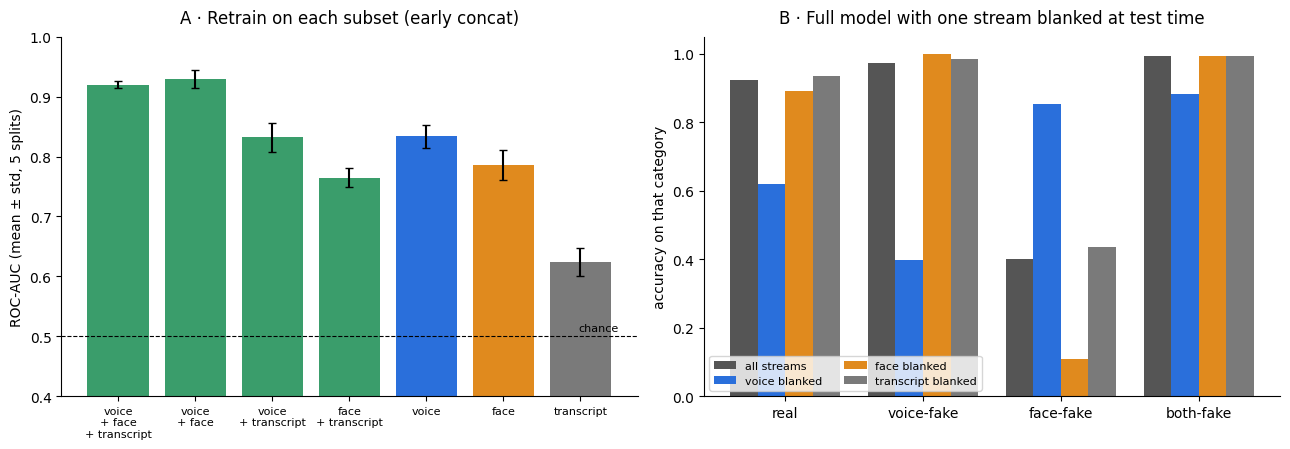

In [8]:
C_V, C_F, C_T = "#2a6fdb", "#e08a1e", "#7a7a7a"
fig, ax = plt.subplots(1, 2, figsize=(13, 4.6))
a = A_mean.loc["Early concat"].reindex(order)
sd = A_std.loc["Early concat"].reindex(order)
cols = [C_V if s == "voice" else C_F if s == "face" else C_T if s == "transcript" else "#3a9d6b" for s in order]
ax[0].bar(range(len(order)), a.auc, yerr=sd.auc, color=cols, capsize=3)
ax[0].axhline(0.5, ls="--", c="k", lw=.8); ax[0].text(len(order) - .5, .505, "chance", ha="right", va="bottom", fontsize=8)
ax[0].set_xticks(range(len(order))); ax[0].set_xticklabels([o.replace(" + ", "\n+ ") for o in order], fontsize=8)
ax[0].set_ylim(0.4, 1.0); ax[0].set_ylabel("ROC-AUC (mean ± std, 5 splits)")
ax[0].set_title("A · Retrain on each subset (early concat)", pad=10)
w = .38
catlab = ["real", "voice-fake", "face-fake", "both-fake"]
bm = B_mean[[f"acc_{c}" for c in CATS]]
for i, (k, lab) in enumerate((("none removed", "all streams"), ("voice blanked", "voice blanked"),
                              ("face blanked", "face blanked"), ("transcript blanked", "transcript blanked"))):
    ax[1].bar(np.arange(4) + (i - 1.5) * .2, bm.loc[k].values, .2, label=lab,
              color=["#555", C_V, C_F, C_T][i])
ax[1].set_xticks(range(4)); ax[1].set_xticklabels(catlab); ax[1].set_ylim(0, 1.05)
ax[1].set_ylabel("accuracy on that category"); ax[1].legend(fontsize=8, ncol=2, loc="lower left")
ax[1].set_title("B · Full model with one stream blanked at test time", pad=10)
for x in ax: x.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig(f"{OUT}/exp4_ablation.png", dpi=150); plt.show()

## 8 · Save everything

In [9]:
print(sorted(os.listdir(OUT)))

['exp4_A_retrain_long.csv', 'exp4_A_retrain_mean.csv', 'exp4_A_retrain_std.csv', 'exp4_B_drop_one.csv', 'exp4_B_test_time_long.csv', 'exp4_B_test_time_mean.csv', 'exp4_ablation.png']
